# Proyecto 3 — Mejorando el clasificador ASL del Lab 3 con CUDA

**CC3069 Computación Paralela y Distribuida · UVG · Semestre II 2026**
Diego López (`dlop6`) · Nicolás Concuá (`NicoCT04`) · Esteban Cárcamo (`ecarcamo`)

Este notebook contiene, ejecutados en la misma máquina, el **código original secuencial** del Laboratorio 3 de Data
Science (clasificador de 29 clases del alfabeto ASL con una CNN) y la **versión optimizada**:

| Fase | Versión secuencial (original) | Versión optimizada | Hardware |
|---|---|---|---|
| Preparación de datos | `for` de Python, una imagen a la vez con PIL | 24 procesos con `multiprocessing` y memoria compartida | **CPU** (núcleos) |
| Entrenamiento | `model.fit` en CPU | `model.fit` en CUDA: precisión mixta, `tf.data`, 32 pasos por llamada | **GPU** |
| Inferencia | `model.predict` en CPU | `model.predict` en GPU + kernels propios en Numba CUDA | **GPU** |

La separación es explícita: todo lo que toca archivos e imágenes ocurre en el CPU (secciones A.1 y B.1). La GPU
recibe únicamente tensores ya preparados y hace la matemática de la red neuronal (secciones A.2, B.2 y B.3).

Las cifras oficiales del informe salen de `scripts/run_all_benchmarks.sh` (varias corridas por configuración) y se
muestran en la Parte C. Lo que se ejecuta en las partes A y B es una corrida de demostración de cada versión.

In [1]:
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.parallel_cpu.dataset import ParallelImageLoader

loader = ParallelImageLoader()

from src.gpu_runtime import load_tensorflow

tf = load_tensorflow("gpu")
print("Procesos para la preparación de datos:", loader.workers)
print("Dispositivos de TensorFlow:", [d.name for d in tf.config.list_logical_devices()])

I0000 00:00:1794807762.616279 1484379 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794807765.263656 1484379 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Procesos para la preparación de datos: 24
Dispositivos de TensorFlow: ['/device:CPU:0', '/device:GPU:0']


El pool de procesos se crea **antes** de cargar TensorFlow. Con `fork`, los trabajadores nacen de un proceso pequeño y
arrancan en milisegundos. Si se crearan después, cada uno heredaría la memoria de TensorFlow y del contexto CUDA.
`load_tensorflow("gpu")` precarga `libcusolver` (ver `README.md`) y activa `memory_growth` en la GPU.

In [2]:
import json

env = json.loads(Path("results/environment.json").read_text())
print("CPU :", env["cpu"]["model"], f"({env['cpu']['physical_cores']} núcleos físicos, {env['cpu']['logical_cores']} lógicos)")
print("GPU :", env["gpu"]["name"], env["gpu"]["memory.total"], "· compute capability", env["numba"]["device"]["compute_capability"],
      "·", env["numba"]["device"]["multiprocessors"], "SM")
print("TF  :", env["tensorflow"]["version"], "· CUDA", env["tensorflow"]["cuda_build"], "· cuDNN", env["tensorflow"]["cudnn_build"])
print("Numba:", env["numba"]["version"])

CPU : 13th Gen Intel(R) Core(TM) i9-13980HX (24 núcleos físicos, 32 lógicos)
GPU : NVIDIA GeForce RTX 4050 Laptop GPU 6141 MiB · compute capability 8.9 · 20 SM
TF  : 2.21.0 · CUDA 12.5.1 · cuDNN 9
Numba: 0.68.1


## Parte A — Código original secuencial (Lab 3)

Funciones trasladadas sin cambios de lógica a `src/sequential/` (responsable: Diego López).

### A.1 Preparación de datos en un solo hilo (CPU)

In [3]:
import inspect
import numpy as np

from src.config import DATA_DIR, SEED
from src.sequential.dataset import list_images, load_set, load_splits, split_dataset

print(inspect.getsource(load_set))

classes, files, labels = list_images(DATA_DIR / "subset")
splits = split_dataset(files, labels)
start = time.perf_counter()
sequential_data = load_splits(splits, classes)
sequential_prep = time.perf_counter() - start
print({name: X.shape for name, (X, y) in sequential_data.items()})
print(f"Preparación secuencial: {sequential_prep:.2f} s")

def load_set(paths, text_labels, class_to_index):
    X = np.zeros((len(paths), *IMAGE_SIZE, 3), dtype=np.float32)
    y = np.zeros(len(paths), dtype=np.int32)
    for i, (path, label) in enumerate(zip(paths, text_labels)):
        img = Image.open(path).resize(IMAGE_SIZE)
        X[i] = np.array(img) / 255.0
        y[i] = class_to_index[label]
    return X, y



{'train': (12180, 64, 64, 3), 'val': (2610, 64, 64, 3), 'test': (2610, 64, 64, 3)}
Preparación secuencial: 8.53 s


### A.2 Entrenamiento e inferencia de la CNN base en CPU (5 épocas)

Se ejecuta `src/sequential/run_sequential.py` en un **proceso aparte con la GPU oculta** (`CUDA_VISIBLE_DEVICES=-1`),
igual que el laboratorio original y que `benchmarks/bench_sequential.py`. Forzar el CPU con `tf.device("/CPU:0")`
dentro de este mismo proceso, que ya inicializó CUDA, no es una medición justa: lo probamos y tardó 108 s en vez de
~41 s, porque TensorFlow sigue coordinando ambos dispositivos.

In [4]:
import re
import subprocess

EPOCHS = 5
result = subprocess.run(
    [sys.executable, "-m", "src.sequential.run_sequential", "--epochs", str(EPOCHS), "--no-early-stop"],
    capture_output=True, text=True, env={**os.environ, "TF_CPP_MIN_LOG_LEVEL": "3"}, check=True,
)
print(result.stdout)
times = re.search(r"entrenamiento ([\d.]+) · inferencia ([\d.]+)", result.stdout)
sequential_train, sequential_infer = float(times.group(1)), float(times.group(2))
X_test, y_test = sequential_data["test"]

Entrenamiento: (12180, 64, 64, 3) Validación: (2610, 64, 64, 3) Prueba: (2610, 64, 64, 3)
Epoch 1/5
381/381 - 8s - 21ms/step - accuracy: 0.3759 - loss: 2.1236 - val_accuracy: 0.7034 - val_loss: 0.9455
Epoch 2/5
381/381 - 7s - 19ms/step - accuracy: 0.8018 - loss: 0.6259 - val_accuracy: 0.8755 - val_loss: 0.3959
Epoch 3/5
381/381 - 8s - 20ms/step - accuracy: 0.9170 - loss: 0.2662 - val_accuracy: 0.9130 - val_loss: 0.2704
Epoch 4/5
381/381 - 8s - 21ms/step - accuracy: 0.9498 - loss: 0.1551 - val_accuracy: 0.9303 - val_loss: 0.2282
Epoch 5/5
381/381 - 8s - 21ms/step - accuracy: 0.9666 - loss: 0.1045 - val_accuracy: 0.9506 - val_loss: 0.1621
CNN base en CPU, accuracy en prueba: 0.9540
Tiempos (s): preparación 8.88 · entrenamiento 39.66 · inferencia 0.92



## Parte B — Versión optimizada

### B.1 Preparación de datos en paralelo con los núcleos del CPU

`ParallelImageLoader` (responsable: Nicolás Concuá) reparte las rutas en tareas de 64 imágenes entre 24 procesos (uno
por núcleo físico). Cada proceso decodifica y redimensiona las imágenes con PIL y escribe los píxeles `uint8`
directamente en un bloque de `multiprocessing.shared_memory`, sin devolver arreglos por `pickle`.

In [5]:
from src.parallel_cpu.dataset import normalize

start = time.perf_counter()
pixels = loader.load_splits(splits, classes, as_float=False)
parallel_prep = time.perf_counter() - start
print(f"Preparación paralela: {parallel_prep:.2f} s (speedup ×{sequential_prep / parallel_prep:.1f})")
print("Idéntica a la secuencial:",
      all(np.array_equal(normalize(pixels[k][0]), sequential_data[k][0]) and np.array_equal(pixels[k][1], sequential_data[k][1])
          for k in pixels))

Preparación paralela: 1.57 s (speedup ×5.4)


Idéntica a la secuencial: True


### B.2 Configuración de CUDA para el entrenamiento

Responsable: Esteban Cárcamo. La red, el optimizador, el batch y las épocas son los mismos que en A.2. Lo único que
cambia es dónde y cómo se ejecuta:

* `tf.keras.mixed_precision.set_global_policy("mixed_float16")`: activa los *tensor cores* de la RTX 4050.
* `make_dataset` (pipeline `tf.data` en el CPU): baraja, arma batches, normaliza `uint8 → float32` y hace `prefetch`
  para que el CPU prepare el siguiente batch mientras la GPU entrena el actual.
* `steps_per_execution=32`: Python despacha 32 pasos de entrenamiento por llamada a la GPU.

Primero se hace un calentamiento corto. La primera vez que un proceso usa CUDA, cuDNN inicializa el contexto y busca el
mejor algoritmo de convolución. Ese costo único se reporta aparte.

In [6]:
import inspect
from src.gpu.train import VARIANTS, build_model, fit, predict, warm_up
from src.parallel_cpu.pipeline import make_dataset

print(inspect.getsource(make_dataset))
variant = VARIANTS["gpu_mixed_tfdata_spe"]
print("Variante:", variant)
print(f"Calentamiento CUDA/cuDNN: {warm_up(tf, variant, pixels):.2f} s")

gpu_model = build_model(tf, variant["mixed"], SEED, variant["steps_per_execution"])
start = time.perf_counter()
fit(tf, gpu_model, pixels, EPOCHS, variant["pipeline"], SEED)
gpu_train = time.perf_counter() - start
start = time.perf_counter()
gpu_probabilities = predict(tf, gpu_model, pixels["test"][0], variant["pipeline"])
gpu_infer = time.perf_counter() - start

print("Pesos en:", gpu_model.weights[0].value.device)
print(f"Entrenamiento GPU: {gpu_train:.2f} s (speedup ×{sequential_train / gpu_train:.1f}) · "
      f"inferencia GPU: {gpu_infer:.2f} s · accuracy prueba: {(gpu_probabilities.argmax(1) == y_test).mean():.4f}")

def make_dataset(tf, pixels, labels, batch_size, shuffle=False, seed=0):
    with tf.device("/CPU:0"):
        dataset = tf.data.Dataset.from_tensor_slices((pixels, labels))
        if shuffle:
            dataset = dataset.shuffle(len(labels), seed=seed, reshuffle_each_iteration=True)
        dataset = dataset.batch(batch_size)
        dataset = dataset.map(
            lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
        return dataset.prefetch(tf.data.AUTOTUNE)

Variante: {'device': 'gpu', 'mixed': True, 'pipeline': True, 'steps_per_execution': 32}


/home/escu/Documentos/Universidad/Semestres/8voSemestre/PARALELA/Proyecto3-Paralela/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Calentamiento CUDA/cuDNN: 9.86 s


E0000 00:00:1794807862.299479 1484379 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Pesos en: /job:localhost/replica:0/task:0/device:GPU:0
Entrenamiento GPU: 14.00 s (speedup ×2.8) · inferencia GPU: 0.57 s · accuracy prueba: 0.9199


### B.3 Kernels propios en CUDA Python (Numba)

La misma arquitectura, ejecutada hacia adelante con kernels escritos con `numba.cuda` (`src/gpu/kernels.py`). La
tabla muestra cómo se reparte el trabajo en hilos, bloques y grids para un batch de 256 imágenes. El diseño completo
está en `docs/04_diseno_cuda.md`.

In [7]:
import pandas as pd
from src.gpu import kernels
from src.gpu.numba_forward import NumbaCnn, export_weights

print(inspect.getsource(kernels.conv3x3_relu_tiled))
cpu_model = tf.keras.models.load_model("models/cnn_base_cpu.keras")
network = NumbaCnn(export_weights(cpu_model))
reference = cpu_model.predict(X_test, batch_size=256, verbose=0)
network.predict(X_test)
start = time.perf_counter()
numba_probabilities, timings = network.predict(X_test)
numba_total = time.perf_counter() - start

print(f"Kernels Numba: {numba_total:.3f} s en total · copia CPU→GPU {timings['h2d_ms']:.1f} ms · "
      f"kernels {timings['kernels_ms']:.1f} ms · copia GPU→CPU {timings['d2h_ms']:.1f} ms")
print(f"Diferencia máxima vs. Keras en GPU (TF32): {np.abs(numba_probabilities - reference).max():.2e} · "
      f"misma clase predicha: {(numba_probabilities.argmax(1) == reference.argmax(1)).mean():.4f}")
pd.DataFrame(network.profile(X_test))

@cuda.jit(fastmath=True)
def conv3x3_relu_tiled(inputs, weights, bias, outputs):
    tile = cuda.shared.array((HALO, HALO), float32)
    acc = cuda.local.array(CHANNELS_PER_THREAD, float32)
    tx = cuda.threadIdx.x
    ty = cuda.threadIdx.y
    x = cuda.blockIdx.x * TILE + tx
    y = cuda.blockIdx.y * TILE + ty
    groups = outputs.shape[1] // CHANNELS_PER_THREAD
    n = cuda.blockIdx.z // groups
    co0 = (cuda.blockIdx.z % groups) * CHANNELS_PER_THREAD
    height = inputs.shape[2]
    width = inputs.shape[3]
    inside = x < width and y < height
    for k in range(CHANNELS_PER_THREAD):
        acc[k] = bias[co0 + k]
    for ci in range(inputs.shape[1]):
        for index in range(ty * TILE + tx, HALO * HALO, TILE * TILE):
            ly = index // HALO
            lx = index % HALO
            gy = cuda.blockIdx.y * TILE + ly - 1
            gx = cuda.blockIdx.x * TILE + lx - 1
            if 0 <= gy < height and 0 <= gx < width:
                tile[ly, lx] = inputs[n, ci, gy, gx]


/home/escu/Documentos/Universidad/Semestres/8voSemestre/PARALELA/Proyecto3-Paralela/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 26 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)
/home/escu/Documentos/Universidad/Semestres/8voSemestre/PARALELA/Proyecto3-Paralela/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 0 variables. 
  saveable.load_own_variables(store)


/home/escu/Documentos/Universidad/Semestres/8voSemestre/PARALELA/Proyecto3-Paralela/.venv/lib/python3.11/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 2 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


/home/escu/Documentos/Universidad/Semestres/8voSemestre/PARALELA/Proyecto3-Paralela/.venv/lib/python3.11/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 50 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/escu/Documentos/Universidad/Semestres/8voSemestre/PARALELA/Proyecto3-Paralela/.venv/lib/python3.11/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Kernels Numba: 0.288 s en total · copia CPU→GPU 17.0 ms · kernels 270.9 ms · copia GPU→CPU 0.3 ms
Diferencia máxima vs. Keras en GPU (TF32): 6.64e-04 · misma clase predicha: 1.0000


,kernel,grid,block,threads,ms
0,to_channels_first,"(4, 4, 768)","(16, 16)",3145728,0.425312
1,conv1_relu,"(4, 4, 1024)","(16, 16)",4194304,2.184832
2,conv1_maxpool,"(2, 2, 8192)","(16, 16)",8388608,0.943104
3,conv2_relu,"(2, 2, 2048)","(16, 16)",2097152,9.974784
4,conv2_maxpool,"(1, 1, 16384)","(16, 16)",4194304,0.488448
5,conv3_relu,"(1, 1, 4096)","(16, 16)",1048576,9.874432
6,conv3_maxpool,"(1, 1, 32768)","(8, 8)",2097152,0.261120
7,flatten,"(32, 256)","(256, 1)",2097152,0.078848
8,dense1_relu,"(1, 256)","(128,)",32768,2.266112
9,dense2,"(1, 256)","(128,)",32768,0.021504


## Parte C — Resultados de los benchmarks

`scripts/run_all_benchmarks.sh` corre todas las configuraciones varias veces (5 corridas en la submuestra, 3 en el
dataset completo) con monitoreo de cada núcleo del CPU y de `nvidia-smi`. `python -m analysis.compare` genera las
tablas y figuras (responsable: Diego López).

In [8]:
from IPython.display import Image, Markdown, display

display(Markdown(Path("results/summary.md").read_text(encoding="utf-8")))

# Resumen de resultados

Generado por `python -m analysis.compare`. Promedio ± desviación estándar.

## Tiempo por fase y speedup

Secuencial: código original del Lab 3 en CPU. Optimizada: carga con 24 procesos + entrenamiento e inferencia en GPU con precisión mixta, `tf.data` y 32 pasos por llamada. El total optimizado suma además la transferencia explícita CPU→GPU del conjunto de entrenamiento.

| fase | secuencial_s | optimizada_s | speedup |
|---|---|---|---|
| Preparación de datos (CPU) | 10.348 ± 2.124 | 1.224 ± 0.255 | 8.45 |
| Entrenamiento (5 épocas) | 41.312 ± 1.697 | 12.086 ± 1.521 | 3.42 |
| Inferencia (2 610 imágenes) | 0.698 ± 0.083 | 0.668 ± 0.247 | 1.05 |
| Total del pipeline | 52.358 ± 2.648 | 14.007 ± 1.203 | 3.74 |

## Escalabilidad de la preparación de datos en CPU

| workers | tiempo_s | speedup_vs_1_proceso | eficiencia | speedup_vs_secuencial |
|---|---|---|---|---|
| 1 | 7.681 ± 0.239 | 1.0 | 1.0 | 1.35 |
| 2 | 4.257 ± 0.059 | 1.8 | 0.9 | 2.43 |
| 4 | 2.463 ± 0.071 | 3.12 | 0.78 | 4.2 |
| 8 | 1.658 ± 0.096 | 4.63 | 0.58 | 6.24 |
| 12 | 1.402 ± 0.064 | 5.48 | 0.46 | 7.38 |
| 16 | 1.287 ± 0.119 | 5.97 | 0.37 | 8.04 |
| 24 | 1.042 ± 0.045 | 7.37 | 0.31 | 9.93 |
| 32 | 1.016 ± 0.031 | 7.56 | 0.24 | 10.19 |

### Dataset completo (87 000 imágenes)

| workers | tiempo_s | speedup_vs_1_proceso | eficiencia |
|---|---|---|---|
| 1 | 35.704 ± 2.029 | 1.0 | 1.0 |
| 4 | 11.177 ± 0.183 | 3.19 | 0.8 |
| 8 | 6.930 ± 0.235 | 5.15 | 0.64 |
| 16 | 4.687 ± 0.200 | 7.62 | 0.48 |
| 24 | 3.772 ± 0.106 | 9.47 | 0.39 |
| 32 | 4.048 ± 0.149 | 8.82 | 0.28 |

## Entrenamiento: CPU vs. GPU

Speedup respecto al entrenamiento original en CPU (TensorFlow usa los 32 hilos).

| configuracion | entrenamiento_s | por_epoca_s | speedup_vs_cpu | accuracy_prueba |
|---|---|---|---|---|
| CPU, 1 hilo (estrictamente secuencial) | 164.541 ± 1.922 | 32.91 | 0.25 | 0.9217 ± 0.0171 |
| CPU, 32 hilos (Lab 3 original) | 41.312 ± 1.697 | 8.26 | 1.0 | 0.9332 ± 0.0063 |
| GPU fp32, arreglos NumPy | 16.286 ± 1.913 | 3.26 | 2.54 | 0.9242 ± 0.0099 |
| GPU fp32 + tf.data | 14.941 ± 1.763 | 2.99 | 2.76 | 0.9356 ± 0.0057 |
| GPU precisión mixta + tf.data | 12.691 ± 1.883 | 2.54 | 3.26 | 0.9336 ± 0.0136 |
| GPU precisión mixta + tf.data + 32 pasos/llamada | 12.086 ± 1.521 | 2.42 | 3.42 | 0.9306 ± 0.0112 |

Costo único de inicialización de CUDA/cuDNN por proceso (calentamiento, no incluido arriba): GPU fp32: 7.7 s; GPU fp32 + tf.data: 9.5 s; GPU mixta + tf.data: 9.4 s; GPU final: 9.4 s.

### Dataset completo (60 900 imágenes de entrenamiento)

| configuracion | entrenamiento_s | por_epoca_s | speedup | accuracy_prueba |
|---|---|---|---|---|
| CPU (32 hilos) + tf.data | 193.280 ± 2.976 | 38.66 | 1.0 | 0.9819 |
| GPU final | 39.085 ± 3.414 | 7.82 | 4.95 | 0.9877 |

## Transferencias CPU ↔ GPU (conjunto de entrenamiento completo)

| dtype | megabytes | h2d_seconds | h2d_gb_per_s | d2h_seconds | d2h_gb_per_s |
|---|---|---|---|---|---|
| float32 | 570.938 | 0.096 | 5.841 | 1.018 | 0.562 |
| uint8 | 142.734 | 0.028 | 5.495 | 0.157 | 0.957 |

## Kernels propios en Numba CUDA (inferencia)

| implementation | seconds | h2d_s | kernels_s | d2h_s |
|---|---|---|---|---|
| keras_gpu | 0.2074 | nan | nan | nan |
| numba_cuda_naive | 0.5655 | 0.0182 | 0.5465 | 0.0005 |
| numba_cuda_tiled | 0.2888 | 0.0175 | 0.2707 | 0.0004 |
| numpy_cpu | 18.7443 | nan | nan | nan |

Diferencia máxima de probabilidades vs. Keras: 2.73e-03; coincidencia de clase predicha: 0.9996.


**01_tiempo_por_fase.png**

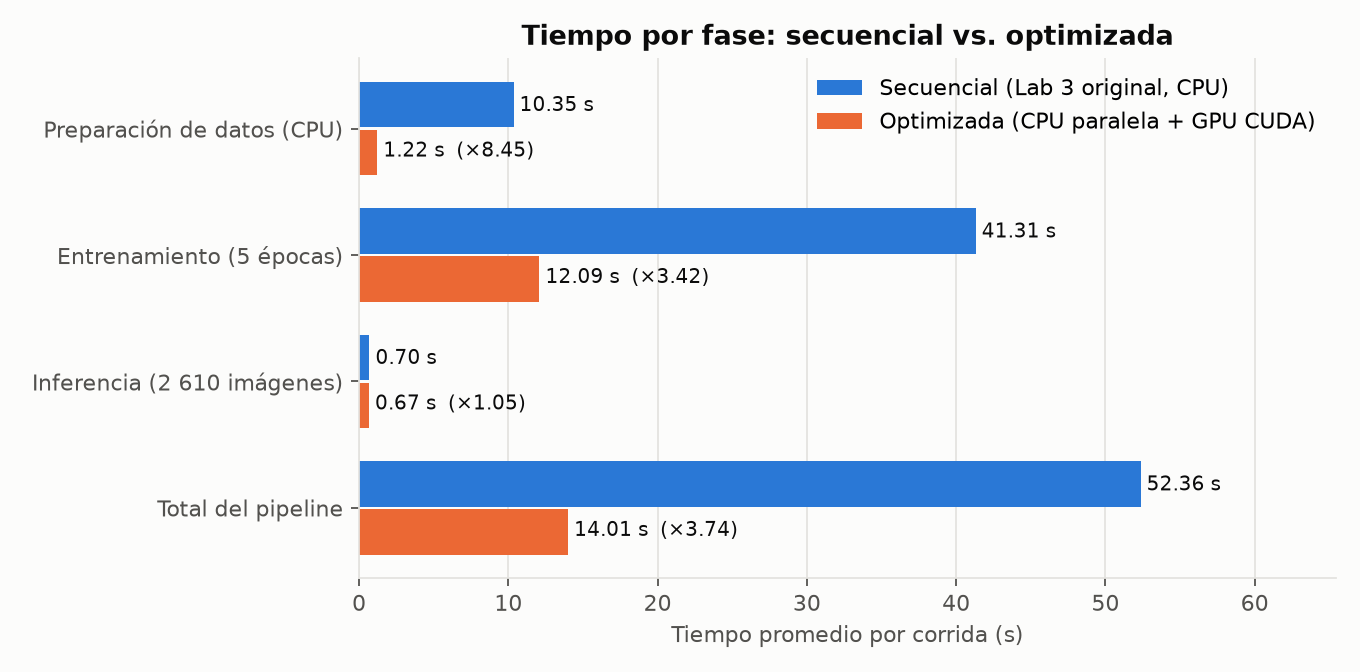

**02_escalabilidad_carga_cpu.png**

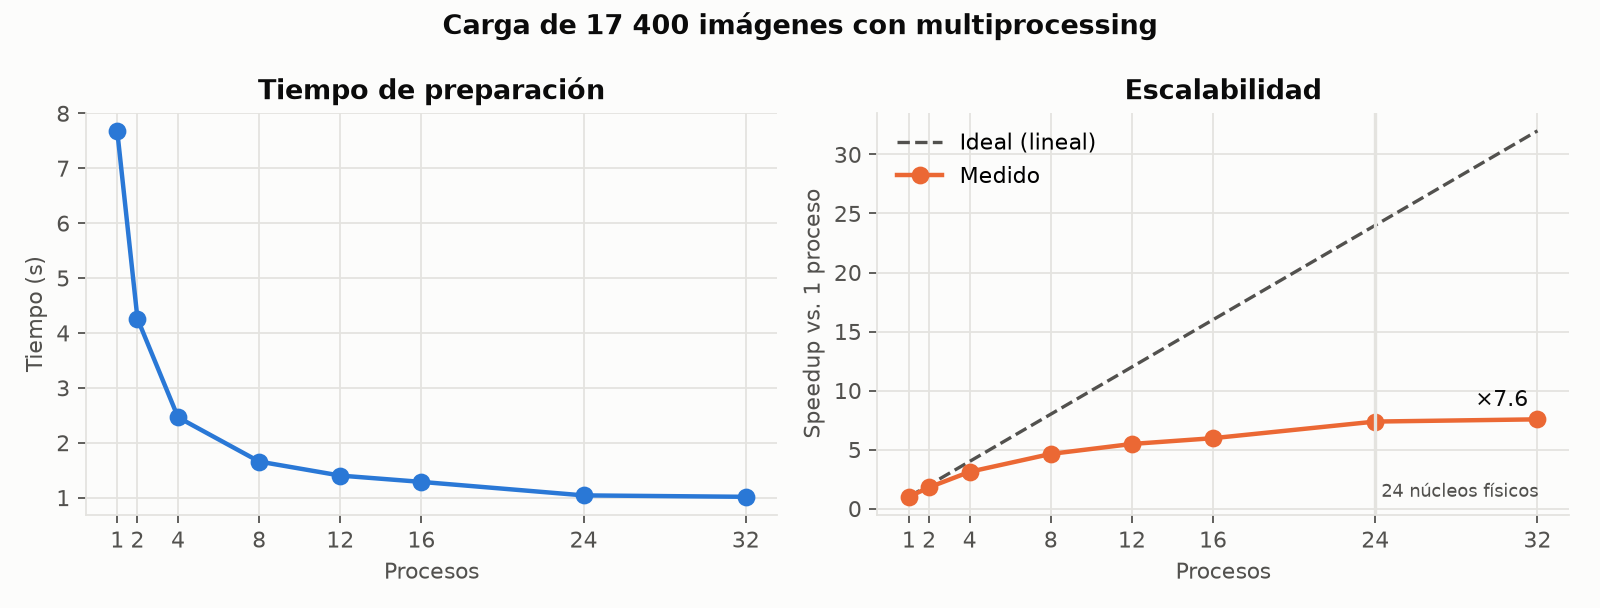

**02b_escalabilidad_carga_cpu_completo.png**

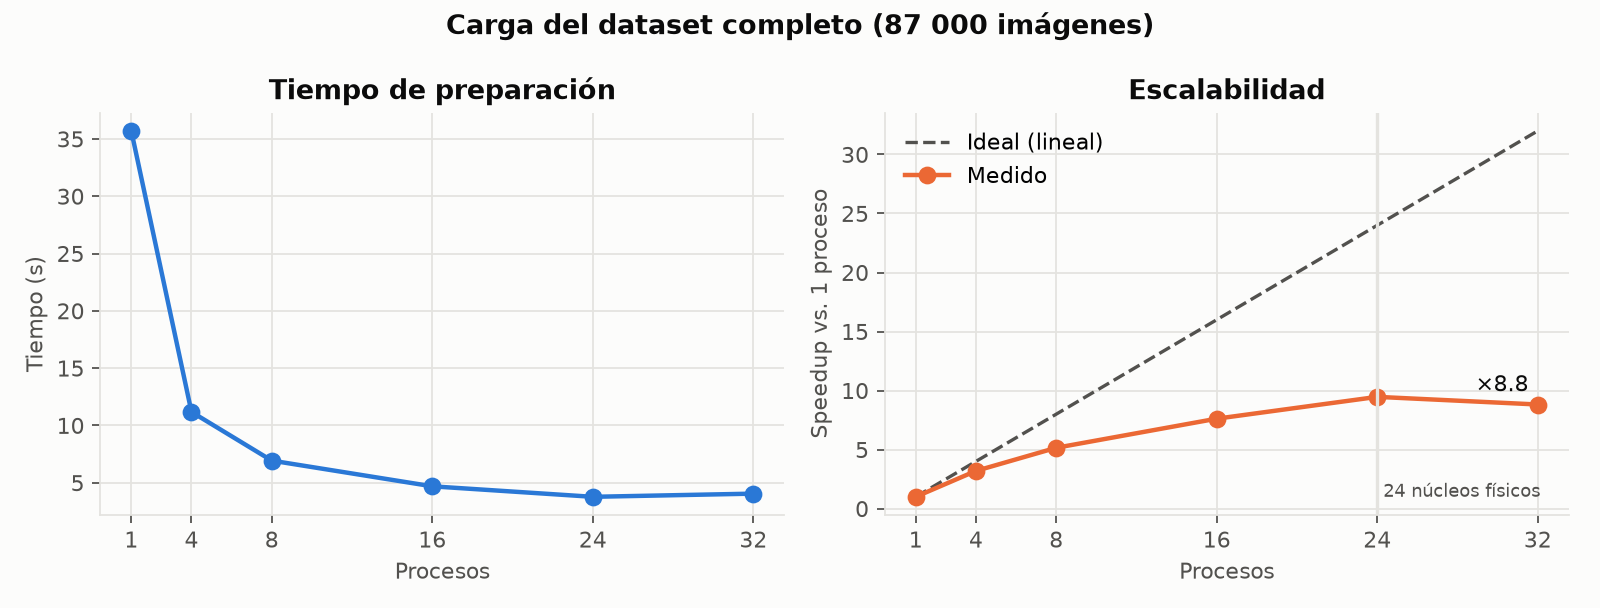

**03_entrenamiento_cpu_vs_gpu.png**

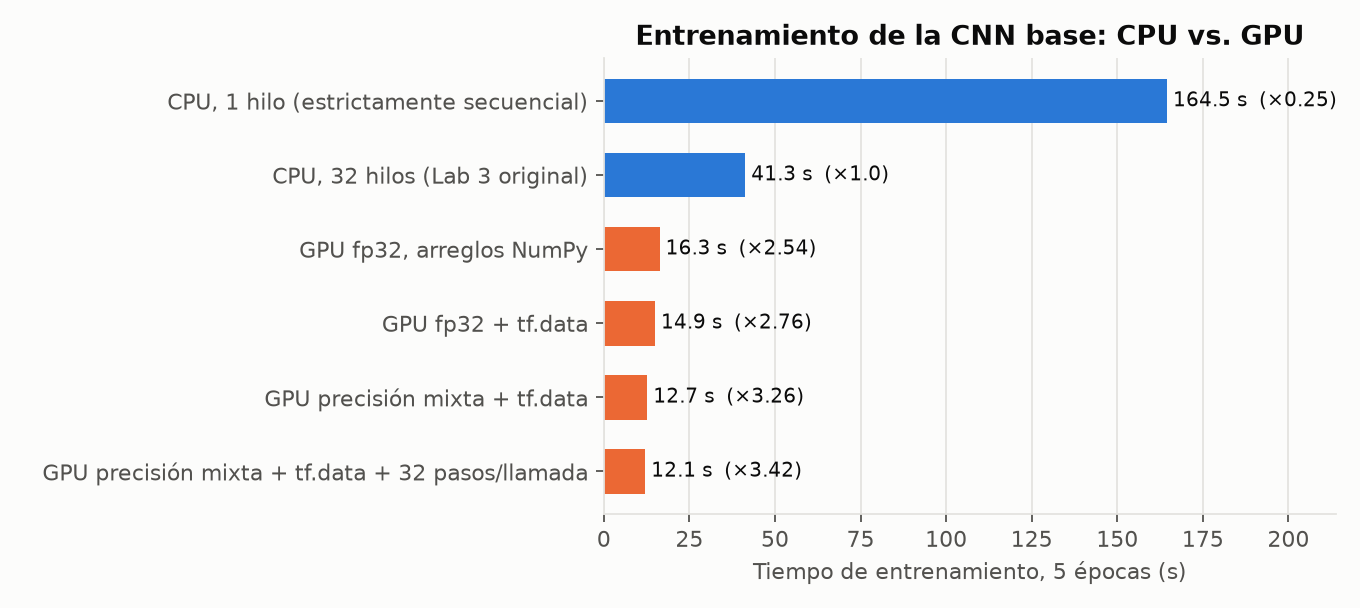

**04_uso_nucleos_cpu.png**

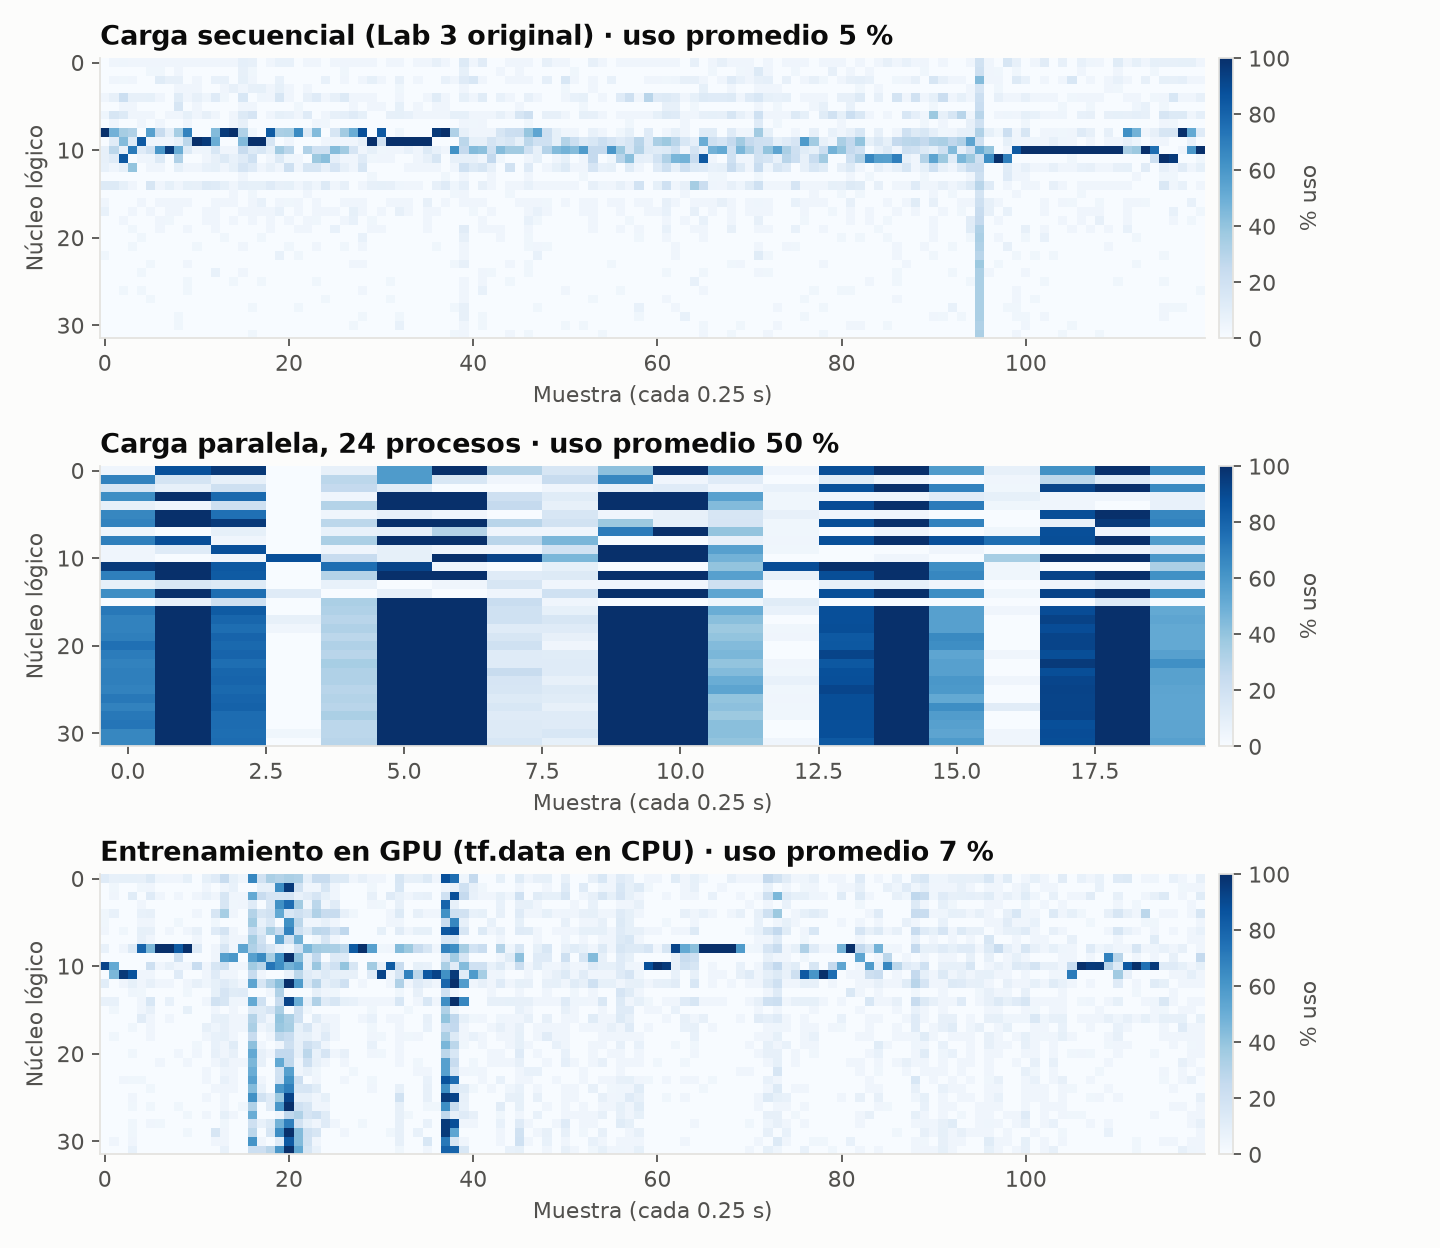

**05_uso_gpu_entrenamiento.png**

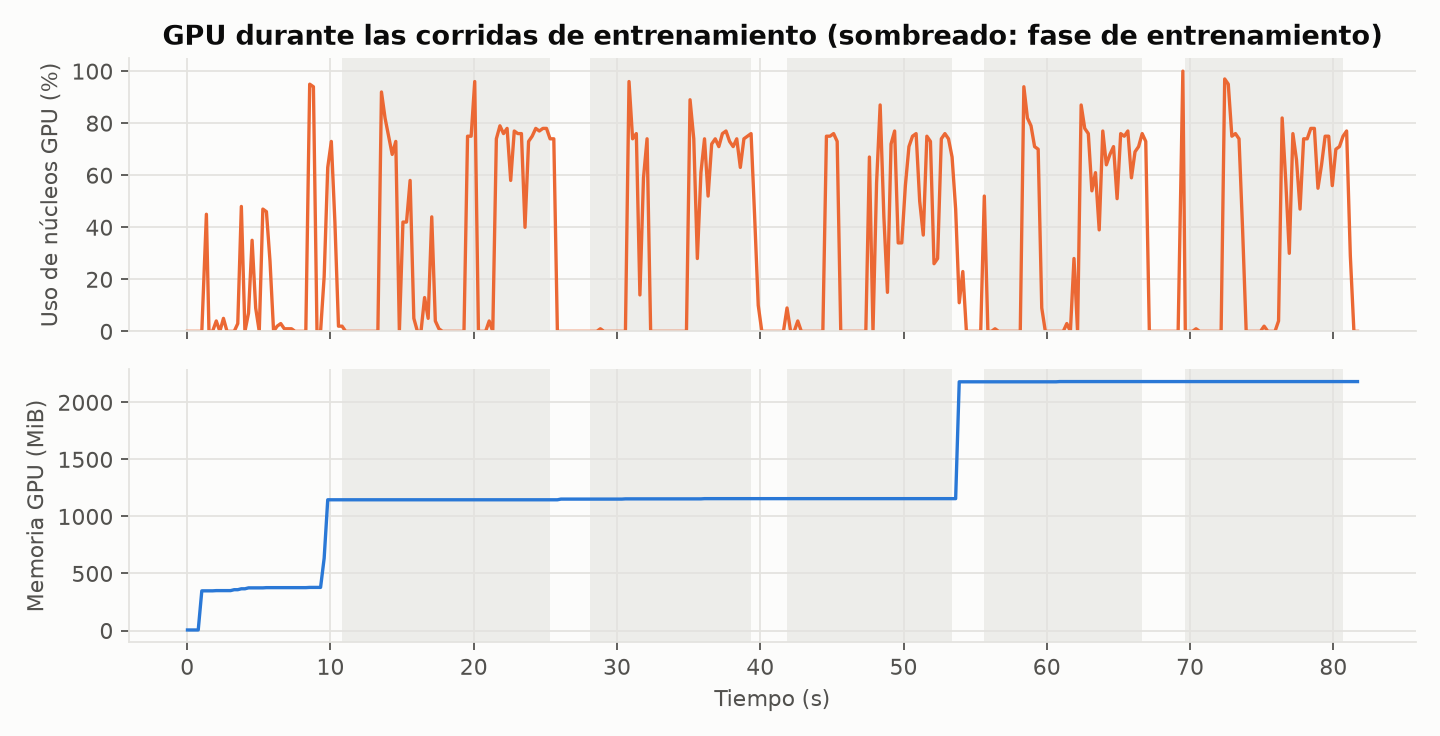

**06_kernels_numba.png**

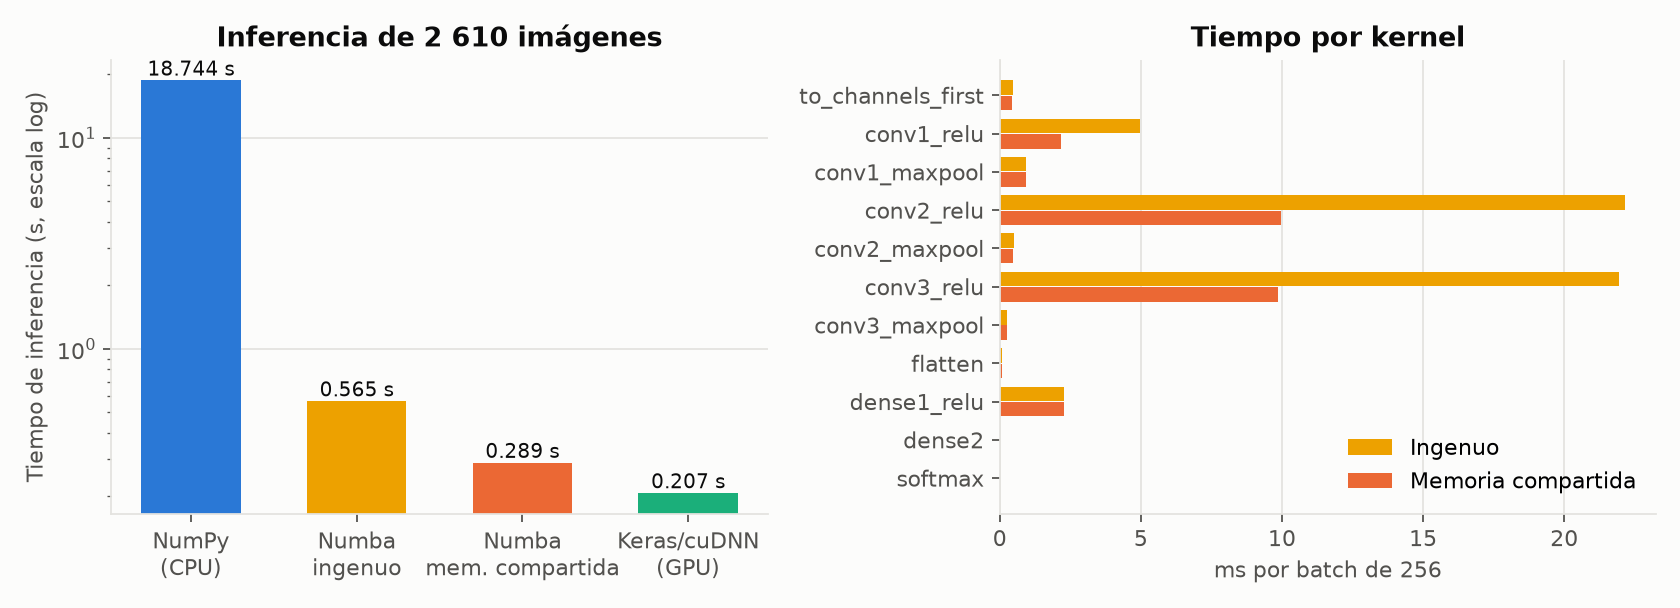

In [9]:
for figure in sorted(Path("figures").glob("*.png")):
    display(Markdown(f"**{figure.name}**"))
    display(Image(filename=str(figure)))

In [10]:
loader.close()

## Conclusión

* Los **archivos** se quedan en el CPU. Decodificar JPEG es trabajo irregular, con ramas y E/S, y cada imagen es
  independiente. Con 24 procesos, la preparación pasa de un núcleo ocupado a 21 núcleos por encima del 50 %.
* La **matemática de la red** va a la GPU: millones de multiplicaciones-sumas idénticas que se reparten entre miles
  de hilos CUDA.
* Con un modelo tan pequeño (1.1 M parámetros, imágenes de 64×64, batch de 32), la GPU pasa buena parte del tiempo
  esperando a que Python le mande el siguiente paso. Las optimizaciones de B.2 atacan justamente ese límite.

El análisis completo está en `report/informe.pdf`.